<a href="https://colab.research.google.com/github/chaimagoutal/ING4-MLDLS-Workshop_1_Tools_and_Libraries/blob/main/TP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print("Matplotlib version:", plt.matplotlib.__version__)
print("Seaborn version:", sns.__version__)



# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3
Matplotlib version: 3.10.0
Seaborn version: 0.13.2


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [28]:
# Initialize S, theta and bias
S = np.array([[10, 4],
              [2, 1],
              [7, 3],
              [1, 2]])

theta = np.array([0.3, 0.7])
bias = 0.5

# 1. Compute linear combination z
z = S @ theta + bias
print("z =", z)

# 2. Compute sigmoid probabilities
probabilities = 1 / (1 + np.exp(-z))
print("Probabilities =", probabilities)

# Identify predicted spam emails
predicted_spam = probabilities >= 0.5
print("Predicted spam =", predicted_spam)

z = [6.3 1.8 4.7 2.2]
Probabilities = [0.99816706 0.85814894 0.9909867  0.90024951]
Predicted spam = [ True  True  True  True]


In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities)
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [4]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [ ]:
# Auto graded cell (log)
# skip it

In [5]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"

# Choose randomly 12 different indexes
indexes = rng.choice(log.index, 12, replace=False)

# Set 12 integer values between 5 and 10
log.loc[indexes, "failed_attempts"] = rng.integers(5, 11, 12)

# Display the log
print(log)

       user  hour  failed_attempts country  duration_min
0    yacine     2                0      DZ          24.0
1    yacine    23                0      FR          23.2
2      nour    11                0      FR           4.8
3     karim     9                0      DZ           4.2
4       ali    17                0      DZ          21.8
..      ...   ...              ...     ...           ...
295    nour    18                0      RU           5.2
296    nour    10                0      DZ           9.5
297  yacine     1                0      DZ           5.0
298   karim    15                2      TN          61.0
299     ali     3                1      DZ           7.2

[300 rows x 5 columns]


In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [6]:
# Insert 10 missing values randomly
# Choose 10 random indexes
missing_indexes = rng.choice(log.index, 10, replace=False)

# Insert missing values (NaN) in the country column
log.loc[missing_indexes, "country"] = np.nan

In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [7]:

# ru_log_at_least_five_attempts = ...
ru_log_at_least_five_attempts = log[
    (log["country"] == "RU") &
    (log["failed_attempts"] >= 5)
]

print(len(ru_log_at_least_five_attempts))

1


In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [8]:

# user_max_failed_attempts =
user_max_failed_attempts = (
    log.groupby("user")["failed_attempts"]
    .sum()
    .sort_values(ascending=False)
)

print(user_max_failed_attempts)

user
karim     51
nour      45
ali       44
yacine    43
sara      36
Name: failed_attempts, dtype: int64


In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [9]:

# log['long_session'] = ...
log['long_session'] = (log['duration_min'] > 30).astype(int)

In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

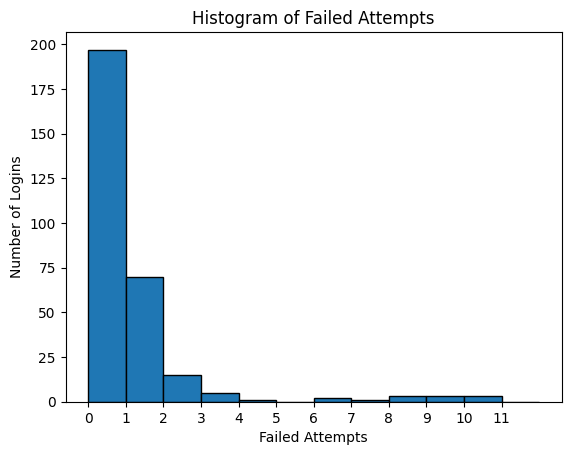

In [10]:
# Draw the histogram of failed_attempts.
plt.hist(log["failed_attempts"], bins=range(0, 13), edgecolor="black")
plt.xlabel("Failed Attempts")
plt.ylabel("Number of Logins")
plt.title("Histogram of Failed Attempts")
plt.xticks(range(0, 12))
plt.show()

In [ ]:
# Auto-graded cell - Skip it...

In [ ]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [ ]:
# Write your code here
# answer_q2 = ...
answer_q2 = B: The distribution is highly skewed with zero-inflation and rare extreme bursts.

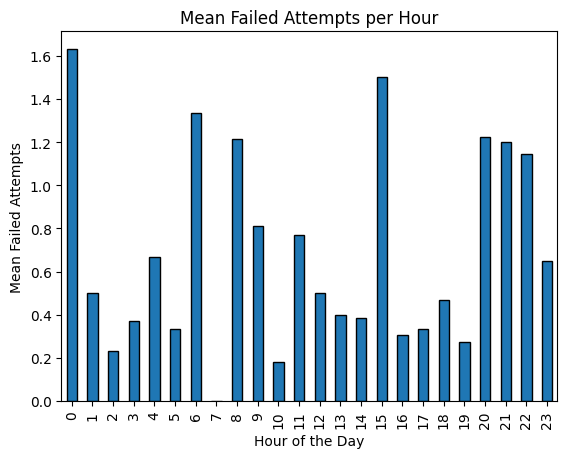

In [11]:
# 3. Draw a bar chart of the mean failed_attempts per night value.
mean_failed_per_hour = log.groupby("hour")["failed_attempts"].mean()

mean_failed_per_hour.plot(kind="bar", edgecolor="black")

plt.xlabel("Hour of the Day")
plt.ylabel("Mean Failed Attempts")
plt.title("Mean Failed Attempts per Hour")
plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
# Write your code here
# Please write a sentence response instead of code
X[:, 2] returns all the elements of the third column of the array X, resulting in a one-dimensional array containing 300 elements.

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [13]:
# Write your code here
log.isnull().sum()

,0
user,0
hour,0
failed_attempts,0
country,10
duration_min,0
long_session,0


Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

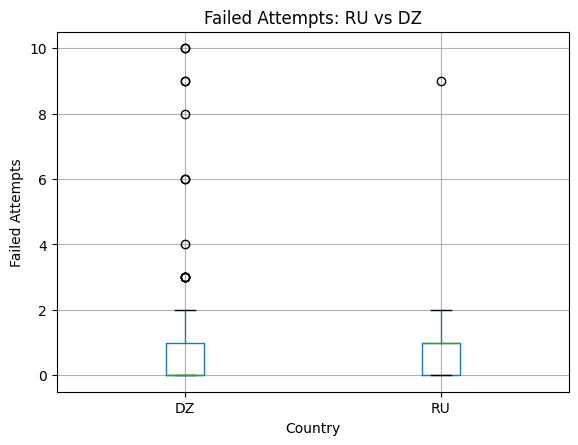

In [14]:
# Write your code here
log[log["country"].isin(["RU", "DZ"])].boxplot(
    column="failed_attempts",
    by="country"
)

plt.title("Failed Attempts: RU vs DZ")
plt.suptitle("")
plt.xlabel("Country")
plt.ylabel("Failed Attempts")
plt.show()

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
# Write your code here
We scale features before training a model to put them on a similar range so that features with larger values do not dominate the learning process.


Commit the logins_clean.csv.(0.5 point)

In [24]:
# save the cleaned table in login_clean.csv
# Write your code here
df = pd.read_csv("login_clean.csv")

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [27]:
# Write your code here
# 1. Load the cleaned CSV file
df = pd.read_csv("login_clean.csv")

# Create the night feature
df["night"] = ((df["hour"] >= 22) | (df["hour"] < 6)).astype(int)

# Select the required columns
cols = ["hour", "failed_attempts", "duration_min", "night"]

# Convert the selected columns into a NumPy matrix
X = df[cols].to_numpy()

# Print the matrix shape
print("Feature matrix shape:", X.shape)

Feature matrix shape: (300, 4)


In [ ]:
import numpy as np
import pandas as pd
